# More advanced CNN architectures

In [1]:
import sys
sys.path.append('..')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import json
import time

from src.utils import creating_datasets
from src.model import SimplestCNN, MediumCNN, DeepCNN
from src.train import train_model, evaluate_on_test

device = torch.device('cpu')

## Load tuned hyperparameters

In [2]:
with open('../models/best_hyperparameters.json', 'r') as f:
    best_params = json.load(f)

LEARNING_RATE = best_params['learning_rate']
BATCH_SIZE = best_params['batch_size']
DROPOUT_RATE = best_params['dropout_rate']

## Load Data

In [3]:
train_dataset, val_dataset, test_dataset = creating_datasets(
    root_dir='../data/raw',
    test_size=0.2,
    val_size=0.1,
    random_state=42
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Training samples: 1531
Validation samples: 219
Test samples: 438


## Train SimplestCNN with tuned parameters

In [4]:
model_simple = SimplestCNN(num_classes=3, dropout_rate=DROPOUT_RATE).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_simple = optim.Adam(model_simple.parameters(), lr=LEARNING_RATE)

start_time = time.time()
history_simple = train_model(
    model=model_simple,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_simple,
    num_epochs=15,
    device=device
)
time_simple = time.time() - start_time

acc_simple = evaluate_on_test(model_simple, test_loader, device)
print(f"\nTest Accuracy: {acc_simple:.4f}, Time: {time_simple:.2f}s")

torch.save(model_simple.state_dict(), '../models/tuned_simplest_cnn.pth')

Epoch [1/15] Train Loss: 1.0716, Train Acc: 0.4285 | Val Loss: 0.9556, Val Acc: 0.5708
Epoch [2/15] Train Loss: 0.8875, Train Acc: 0.5944 | Val Loss: 0.7794, Val Acc: 0.7763
Epoch [3/15] Train Loss: 0.7106, Train Acc: 0.7446 | Val Loss: 0.5091, Val Acc: 0.9224
Epoch [4/15] Train Loss: 0.4760, Train Acc: 0.8478 | Val Loss: 0.2865, Val Acc: 0.9452
Epoch [5/15] Train Loss: 0.3622, Train Acc: 0.8883 | Val Loss: 0.2477, Val Acc: 0.9269
Epoch [6/15] Train Loss: 0.2759, Train Acc: 0.9131 | Val Loss: 0.1624, Val Acc: 0.9589
Epoch [7/15] Train Loss: 0.2367, Train Acc: 0.9308 | Val Loss: 0.1418, Val Acc: 0.9543
Epoch [8/15] Train Loss: 0.2184, Train Acc: 0.9353 | Val Loss: 0.1314, Val Acc: 0.9589
Epoch [9/15] Train Loss: 0.2081, Train Acc: 0.9308 | Val Loss: 0.1289, Val Acc: 0.9726
Epoch [10/15] Train Loss: 0.1796, Train Acc: 0.9458 | Val Loss: 0.1016, Val Acc: 0.9589
Epoch [11/15] Train Loss: 0.1738, Train Acc: 0.9445 | Val Loss: 0.1529, Val Acc: 0.9589
Epoch [12/15] Train Loss: 0.1381, Train A

## Train MediumCNN

In [5]:
model_medium = MediumCNN(num_classes=3, dropout_rate=DROPOUT_RATE).to(device)
optimizer_medium = optim.Adam(model_medium.parameters(), lr=LEARNING_RATE)

start_time = time.time()
history_medium = train_model(
    model=model_medium,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_medium,
    num_epochs=15,
    device=device
)
time_medium = time.time() - start_time

acc_medium = evaluate_on_test(model_medium, test_loader, device)
print(f"\nTest Accuracy: {acc_medium:.4f}, Time: {time_medium:.2f}s")

torch.save(model_medium.state_dict(), '../models/medium_cnn.pth')

Epoch [1/15] Train Loss: 1.0709, Train Acc: 0.4030 | Val Loss: 1.0597, Val Acc: 0.3562
Epoch [2/15] Train Loss: 0.8943, Train Acc: 0.5356 | Val Loss: 0.9678, Val Acc: 0.4977
Epoch [3/15] Train Loss: 0.7056, Train Acc: 0.6839 | Val Loss: 0.5479, Val Acc: 0.6530
Epoch [4/15] Train Loss: 0.3962, Train Acc: 0.8746 | Val Loss: 0.2857, Val Acc: 0.8767
Epoch [5/15] Train Loss: 0.2224, Train Acc: 0.9327 | Val Loss: 0.3956, Val Acc: 0.8904
Epoch [6/15] Train Loss: 0.1496, Train Acc: 0.9517 | Val Loss: 0.1820, Val Acc: 0.9543
Epoch [7/15] Train Loss: 0.1237, Train Acc: 0.9641 | Val Loss: 0.1971, Val Acc: 0.9635
Epoch [8/15] Train Loss: 0.1385, Train Acc: 0.9595 | Val Loss: 0.1650, Val Acc: 0.9543
Epoch [9/15] Train Loss: 0.1313, Train Acc: 0.9582 | Val Loss: 0.1711, Val Acc: 0.9361
Epoch [10/15] Train Loss: 0.1178, Train Acc: 0.9673 | Val Loss: 0.0355, Val Acc: 0.9909
Epoch [11/15] Train Loss: 0.1202, Train Acc: 0.9654 | Val Loss: 0.0883, Val Acc: 0.9772
Epoch [12/15] Train Loss: 0.0881, Train A

## Train DeepCNN

In [6]:
model_deep = DeepCNN(num_classes=3, dropout_rate=DROPOUT_RATE).to(device)
optimizer_deep = optim.Adam(model_deep.parameters(), lr=LEARNING_RATE)

start_time = time.time()
history_deep = train_model(
    model=model_deep,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_deep,
    num_epochs=15,
    device=device
)
time_deep = time.time() - start_time

acc_deep = evaluate_on_test(model_deep, test_loader, device)
print(f"\nDeepCNN - Test Accuracy: {acc_deep:.4f}, Time: {time_deep:.2f}s")

torch.save(model_deep.state_dict(), '../models/deep_cnn.pth')

Epoch [1/15] Train Loss: 1.1536, Train Acc: 0.3592 | Val Loss: 1.0774, Val Acc: 0.3333
Epoch [2/15] Train Loss: 0.9166, Train Acc: 0.5251 | Val Loss: 0.6446, Val Acc: 0.6210
Epoch [3/15] Train Loss: 0.7148, Train Acc: 0.6604 | Val Loss: 0.5122, Val Acc: 0.8447
Epoch [4/15] Train Loss: 0.5947, Train Acc: 0.7446 | Val Loss: 0.6059, Val Acc: 0.6712
Epoch [5/15] Train Loss: 0.4294, Train Acc: 0.8413 | Val Loss: 0.3132, Val Acc: 0.9041
Epoch [6/15] Train Loss: 0.2587, Train Acc: 0.9203 | Val Loss: 0.4328, Val Acc: 0.8539
Epoch [7/15] Train Loss: 0.1768, Train Acc: 0.9438 | Val Loss: 0.1021, Val Acc: 0.9680
Epoch [8/15] Train Loss: 0.1882, Train Acc: 0.9425 | Val Loss: 0.2072, Val Acc: 0.9543
Epoch [9/15] Train Loss: 0.1610, Train Acc: 0.9491 | Val Loss: 0.1601, Val Acc: 0.9452
Epoch [10/15] Train Loss: 0.1126, Train Acc: 0.9621 | Val Loss: 0.1542, Val Acc: 0.9635
Epoch [11/15] Train Loss: 0.1063, Train Acc: 0.9654 | Val Loss: 0.0961, Val Acc: 0.9680
Epoch [12/15] Train Loss: 0.1177, Train A

## Model Comparison

In [7]:
import pandas as pd

comparison_df = pd.DataFrame({
    'Model': ['SimplestCNN', 'MediumCNN', 'DeepCNN'],
    'Conv Layers': [2, 4, 6],
    'Test Accuracy': [acc_simple, acc_medium, acc_deep],
    'Training Time (s)': [time_simple, time_medium, time_deep]
})

print(comparison_df.to_string(index=False))

best_model_idx = comparison_df['Test Accuracy'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']

      Model  Conv Layers  Test Accuracy  Training Time (s)
SimplestCNN            2       0.963470         433.041413
  MediumCNN            4       0.933790         580.993114
    DeepCNN            6       0.956621        1037.559209


## Visualize Comparison

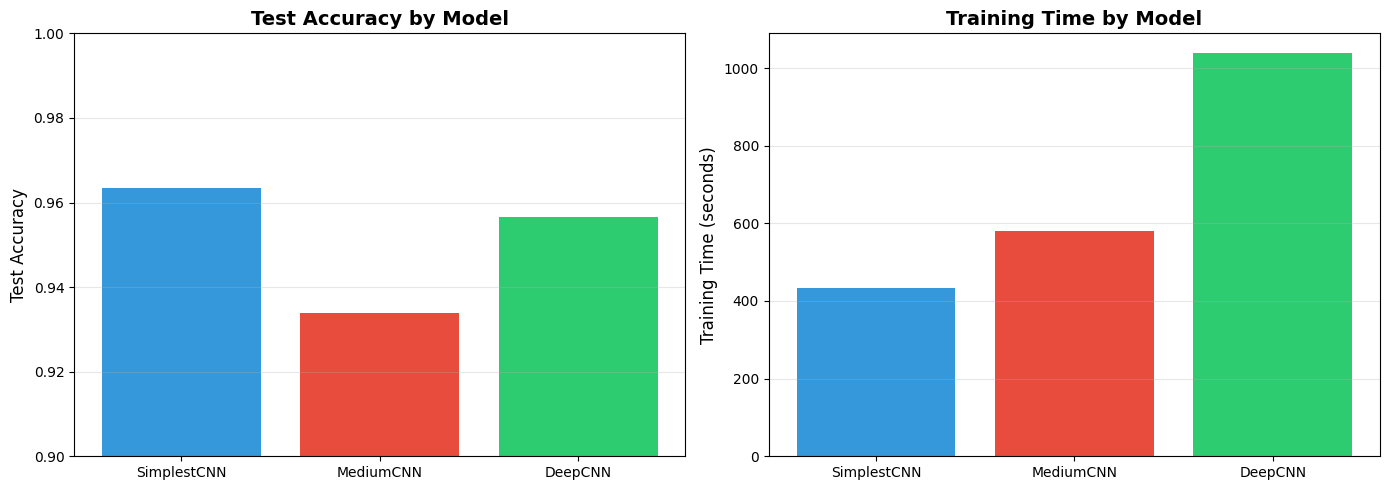

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(comparison_df['Model'], comparison_df['Test Accuracy'], color=['#3498db', '#e74c3c', '#2ecc71'])
axes[0].set_ylabel('Test Accuracy', fontsize=12)
axes[0].set_title('Test Accuracy by Model', fontsize=14, fontweight='bold')
axes[0].set_ylim([0.9, 1.0])
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(comparison_df['Model'], comparison_df['Training Time (s)'], color=['#3498db', '#e74c3c', '#2ecc71'])
axes[1].set_ylabel('Training Time (seconds)', fontsize=12)
axes[1].set_title('Training Time by Model', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Training Curves Comparison

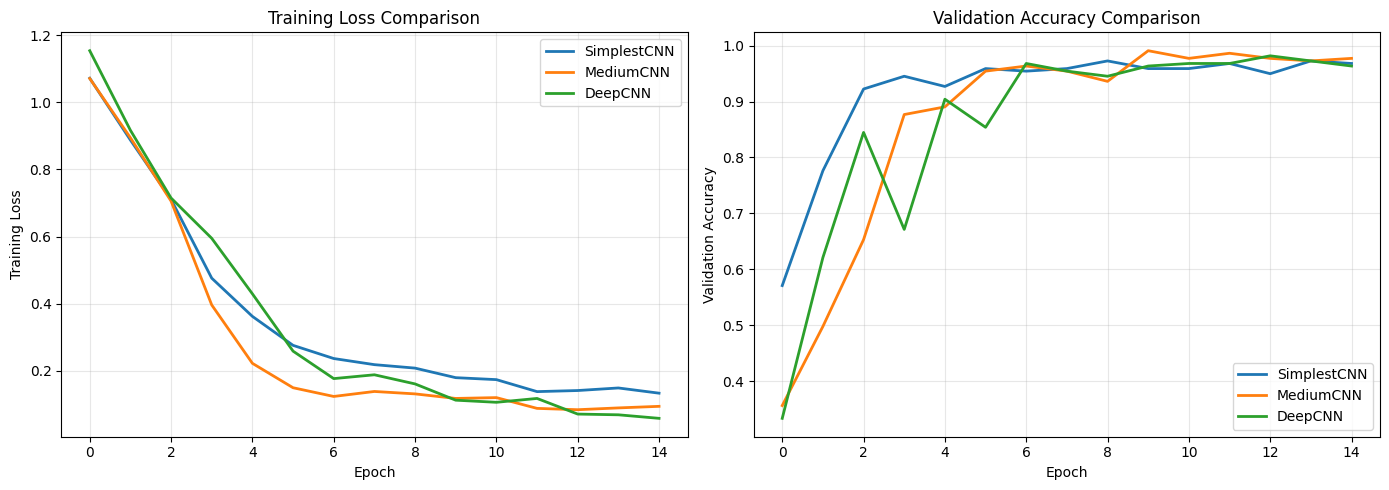

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_simple['train_loss'], label='SimplestCNN', linewidth=2)
axes[0].plot(history_medium['train_loss'], label='MediumCNN', linewidth=2)
axes[0].plot(history_deep['train_loss'], label='DeepCNN', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss Comparison')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_simple['val_acc'], label='SimplestCNN', linewidth=2)
axes[1].plot(history_medium['val_acc'], label='MediumCNN', linewidth=2)
axes[1].plot(history_deep['val_acc'], label='DeepCNN', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Validation Accuracy Comparison')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/training_curves_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Save Comparison Results

In [10]:
comparison_df.to_csv('../reports/model_comparison_results.csv', index=False)